# Fitted microscope: virtual source → smiley → image or diffraction

This interactive example uses the saved fitted microscope from
`microscope_calibration_pipeline.ipynb`, also used by the convergence-angle example.
The portable parameter snapshot is `smiley_calibration.json`; its provenance is
recorded inside. These are fitted **synthetic** microscope parameters, not a
real-instrument calibration. All lenses are native finite `HardEdgeSolenoid`s.

At **200 kV**, start at **40,000×**, spot 3, aperture out. Select detector imaging
or the IL1 diffraction crossover. Adjust specimen height, condenser spot,
aperture, magnification, objective aberrations and signed PL1 distortion.
The source waist, mean position and tilt come from the fit. This is a **coherent
member** of the fitted source; the fit's additional incoherent angular spread
is not averaged into this coherent-wave demonstration.

Run all cells with the notebook extras and preferably a JAX GPU. The **Gaussians**
selector offers 10,000–1,000,000 specimen beamlets (500,000 by default). Low counts
are previews; verify convergence for quantitative results. Each optical/basis
combination compiles once and has its own image cache.


In [8]:
from pathlib import Path
import os
import sys
from time import perf_counter
from types import SimpleNamespace

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/temgym_core").is_dir())
sys.path.insert(0, str(repo / "src"))
sys.path.insert(0, str(repo / "examples/microscope_models"))

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import ipywidgets as widgets
from IPython.display import display
from importlib import reload
import smiley_defocus
SmileyDefocus = reload(smiley_defocus).SmileyDefocus
from temgym_core.run import column_matrix
from temgym_core.evaluate import evaluate_gaussians

%matplotlib inline
print("JAX:", jax.__version__, "Devices:", jax.devices())

JAX: 0.10.2 Devices: [CudaDevice(id=0)]


In [9]:
start = perf_counter()
demo = SmileyDefocus(lattice_shape=(500, 1000))
assert demo.num_beams == 500_000
incident = demo.incident_beamlets(jnp.asarray(0., dtype=jnp.float64))
assert incident.x.shape == (500_000,)
del incident
print(f"Setup: {perf_counter()-start:.2f} s; {demo.num_beams:,} Gaussian beamlets")
print(f"Detector: {demo.detector.shape}, {demo.detector.pixel_size[0]*1e6:g} µm pitch")
print(f"Specimen-equivalent pixel: {demo.detector.pixel_size[0]/demo.magnification*1e9:.3f} nm")
print("Renderer:", demo.method)
print("Column: fitted source → CL1 → CL3 → C_mini → Obj_prefield")
print("        → smiley → aberration action + finite objective → IL1 → IL2 → IL3 → PL1 → detector")
if demo.method == "scan":
    print("CPU fallback: expect slower updates at the full beam count.")

Setup: 13.49 s; 500,000 Gaussian beamlets
Detector: (128, 128), 55 µm pitch
Specimen-equivalent pixel: 1.375 nm
Renderer: spatial
Column: fitted source → CL1 → CL3 → C_mini → Obj_prefield
        → smiley → aberration action + finite objective → IL1 → IL2 → IL3 → PL1 → detector


The fitted source has a waist of approximately **7.2 nm RMS** at its fitted
virtual-source plane. The original artificial 100 nm specimen-waist source is
removed. A single fixed amplitude normalization gives unit nominal specimen
peak intensity; spot/aperture changes retain that normalization.

Spot controls use the calibration's native `design_condenser_curve`: source-image
magnification varies while the mini and objective prefield controls stay fixed.
They produce nearly parallel illumination and a first source crossover between
CL1 and CL3. Spot 1–8 narrows the coherent specimen amplitude radius from roughly
270 to 24 nm; spot 3 is about 135 nm. Magnification explicitly solves the native
IL1–PL1 controls while holding the objective fixed and retaining the calibrated
reference rotation. Finite lens lengths and magnetic rotations are preserved.

Without an aperture, specimen-resolving Gaussians are mapped back to the fitted
source and then propagated continuously. Their lattice covers the full incident
wave, not a fixed detector-sized crop. With an aperture, a separate source bundle
resolves its transmitted field and a **2D complex-field** lookup recomposes it
at the specimen. This handles the fitted offsets; it does not assume radial
symmetry. The selected full specimen count then propagates downstream.

The specimen is the original 140 nm smiley, amplitude-normalized, bounded,
smoothed over about 1.1 nm and given up to 0.8 rad phase. Intensity is
**|sum of complex Gaussian fields|²**, point-sampled on a 128×128 screen.
It is not a ray histogram or pixel-integrated camera simulation.

Objective `KrivanekLens` aberration action supplements the native finite
objective. An adjacent inverse ideal kick removes only the extra thin-lens
focusing, leaving the native lens intact. Its angle scale uses the finite
objective's effective focal length. PL1's Seidel action is similarly an
additional aberration at the native projector entrance. Zero coefficients
recover the fitted native column exactly. Strong aberrations need convergence
checks before quantitative interpretation.


In [10]:
# Warm compilation, then time fresh renders. The display also caches visited heights.
focus, cold_seconds, _ = demo.image(0.)
heights_um = (-10., 0., 10.)
preview = {}
warm_seconds = []
for height_um in heights_um:
    frame, seconds, _ = demo.image(height_um*1000., use_cache=False)
    preview[height_um] = frame
    demo.cache[height_um*1000.] = frame
    warm_seconds.append(seconds)
    print(f"Height {height_um:+5.1f} µm: {1000*seconds:7.1f} ms, including host copy")
print(f"First render, including compilation: {cold_seconds:.2f} s")

# Independent focus check: magnify and rotate the prescribed exit-wave intensity.
M = np.asarray(column_matrix(demo.downstream, source_z=demo.z_sample,
                             voltage=demo.model.voltage))
A = M[:2, :2]
np.testing.assert_allclose(np.linalg.svd(A, compute_uv=False), demo.magnification, rtol=1e-8)
np.testing.assert_allclose(M[:2, 2:4], 0., atol=1e-9)
object_coords = jnp.asarray(np.asarray(demo.detector.coords) @ np.linalg.inv(A).T)
object_grid = SimpleNamespace(coords=object_coords, shape=demo.detector.shape)
illumination_field = evaluate_gaussians(demo.nominal_illumination, object_grid, method="scan")
actions = demo.sample.evaluate_actions(object_coords)
reference = np.asarray(jnp.abs(illumination_field)**2 *
                       jnp.exp(2*actions[:, 1]).reshape(demo.detector.shape))
focus_error = np.linalg.norm(focus-reference) / np.linalg.norm(reference)
assert focus_error < 0.02, f"Focused transmission mismatch: {focus_error:.2%}"
print(f"Focused image vs direct transmission: {focus_error:.2%} relative L2 error")
for height_um in (-10., 10.):
    difference = np.linalg.norm(preview[height_um]-focus) / np.linalg.norm(focus)
    assert difference > 0.02
    shifted = np.asarray(column_matrix(demo.downstream,
        source_z=demo.z_sample+height_um*1e-6, voltage=demo.model.voltage))
    # Positive sample height is downstream: equivalent defocus B/A = -height.
    np.testing.assert_allclose(np.linalg.solve(shifted[:2, :2], shifted[:2, 2:4]),
                               -height_um*1e-6*np.eye(2), atol=1e-12)
    print(f"Height {height_um:+g} µm changes intensity by {difference:.1%} relative L2")
rotation_deg = np.degrees(np.arctan2(A[1, 0], A[0, 0]))
print(f"Image rotation: {rotation_deg:.1f}° (retained on the detector)")

Height -10.0 µm:   121.0 ms, including host copy
Height  +0.0 µm:    78.2 ms, including host copy
Height +10.0 µm:   120.2 ms, including host copy
First render, including compilation: 11.18 s
Focused image vs direct transmission: 0.98% relative L2 error
Height -10 µm changes intensity by 13.1% relative L2
Height +10 µm changes intensity by 8.5% relative L2
Image rotation: -25.4° (retained on the detector)


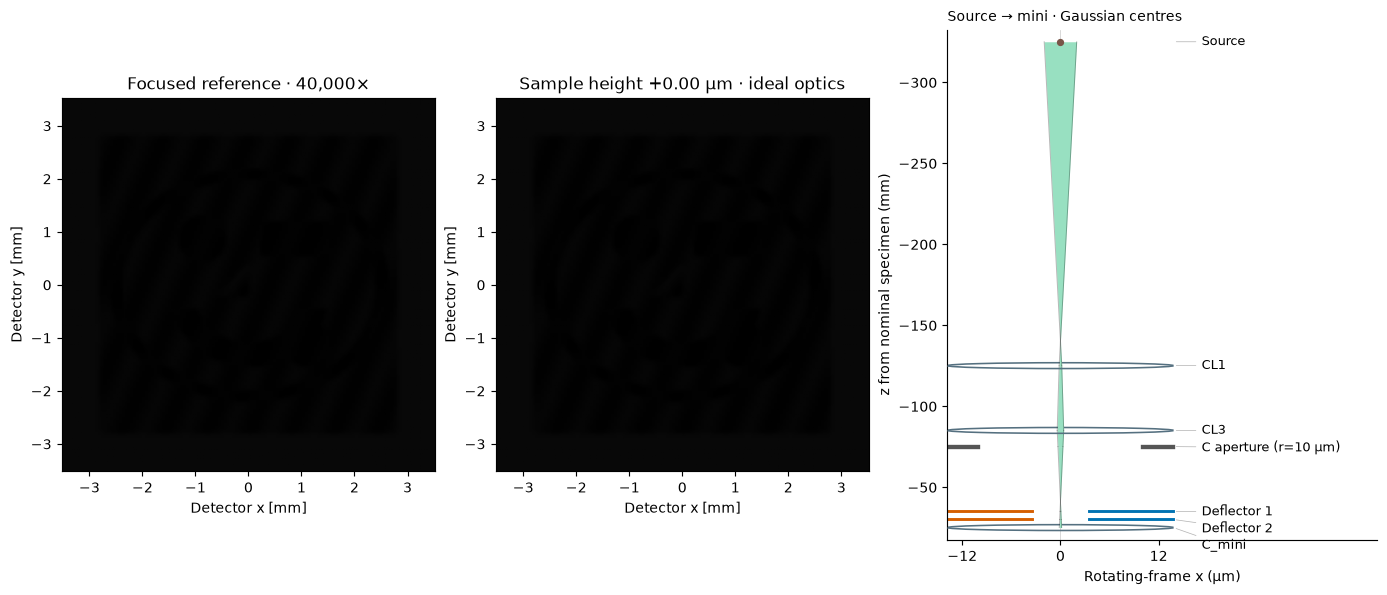

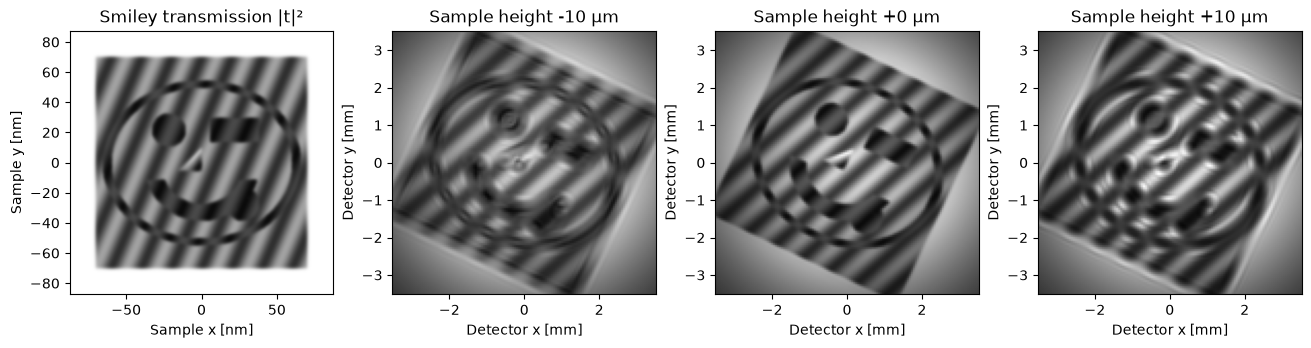

In [11]:
# Saved preview: common intensity scale, with no per-frame renormalization.
# Use pixel edges and the detector's row direction so +y stays upward.
xy = np.asarray(demo.detector.coords).reshape(128, 128, 2)
dy, dx = demo.detector.pixel_size
extent_mm = np.array([xy[..., 0].min()-dx/2, xy[..., 0].max()+dx/2,
                      xy[..., 1].min()-dy/2, xy[..., 1].max()+dy/2])*1e3
detector_origin = "upper" if xy[0, 0, 1] > xy[-1, 0, 1] else "lower"
half_sample_nm = demo.sample_map_width_m*1e9/2
vmax = max(float(frame.max()) for frame in preview.values())
fig, axes = plt.subplots(1, 4, figsize=(13, 3.7), constrained_layout=True)
axes[0].imshow(demo.sample_amplitude**2, origin="lower", cmap="gray", vmin=0, vmax=1,
               extent=(-half_sample_nm, half_sample_nm, -half_sample_nm, half_sample_nm))
axes[0].set(title="Smiley transmission |t|²", xlabel="Sample x [nm]", ylabel="Sample y [nm]")
for ax, height_um in zip(axes[1:], heights_um):
    ax.imshow(preview[height_um], origin=detector_origin, cmap="gray", vmin=0, vmax=vmax,
              extent=extent_mm)
    ax.set(title=f"Sample height {height_um:+g} µm", xlabel="Detector x [mm]", ylabel="Detector y [mm]")
plt.show()

### Objective aberrations on the fitted finite lens

The examples share an intensity scale. Zero coefficients are checked against
the original fitted solenoid column with identical Gaussian illumination.


Astigmatism C₁₂ = 10 µm: 108.9 ms; image change 7.9%
Coma C₂₁ = 20 mm: 88.2 ms; image change 4.4%
Spherical C₃₀ = 50 m: 84.5 ms; image change 0.6%
Zero-coefficient KrivanekLens reproduces the original magnetic objective.


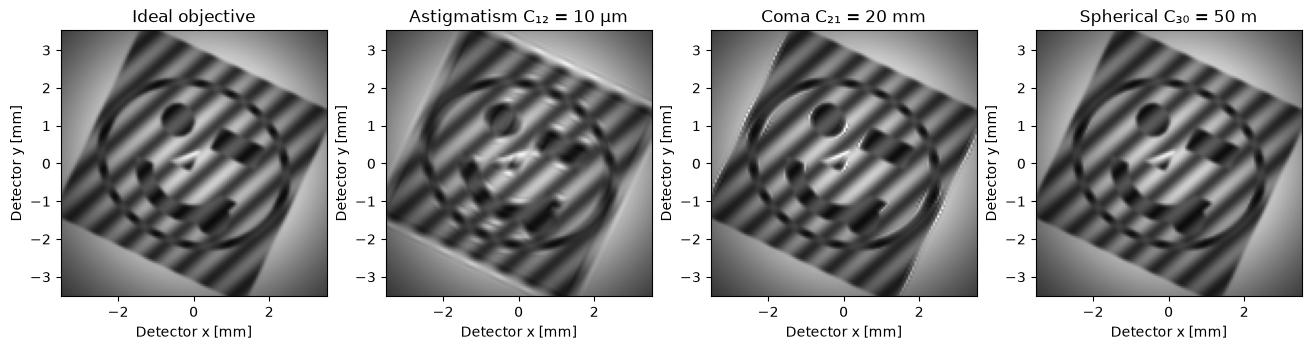

In [12]:
aberration_examples = [
    ("Astigmatism C₁₂ = 10 µm", dict(astigmatism_um=10.)),
    ("Coma C₂₁ = 20 mm", dict(coma_mm=20.)),
    ("Spherical C₃₀ = 50 m", dict(spherical_mm=50_000.)),
]
aberration_frames = []
for label, coefficients in aberration_examples:
    frame, seconds, _ = demo.image(0., **coefficients)
    change = np.linalg.norm(frame-focus)/np.linalg.norm(focus)
    assert change > 0.005, (label, change)
    aberration_frames.append(frame)
    print(f"{label}: {seconds*1000:.1f} ms; image change {change:.1%}")

from temgym_core.components import KrivanekLens
from temgym_core.run import run_to_end
assert isinstance(demo.objective_column()[0], KrivanekLens)
coefficients = demo.objective_column(10., 20., 50_000.)[0].coeffs
np.testing.assert_allclose([coefficients.C12, coefficients.C21, coefficients.C30],
                           [10e-6, 20e-3, 50.], rtol=1e-14)

@jax.jit
def original_ideal_image(height_nm):
    from dataclasses import replace
    sample = replace(demo.sample, z=demo.z_sample+height_nm*1e-9)
    output = run_to_end(demo.incident_beamlets(height_nm), (sample, *demo.downstream),
                        propagator=demo.propagator)
    field = evaluate_gaussians(output, demo.detector, method=demo.method, tile_beams=32)
    return jnp.abs(field*demo.magnification)**2

original_focus = np.asarray(original_ideal_image(jnp.asarray(0.)))
np.testing.assert_allclose(focus, original_focus, rtol=1e-7, atol=1e-9)
print("Zero-coefficient KrivanekLens reproduces the original magnetic objective.")
aber_fig, aber_axes = plt.subplots(1, 4, figsize=(13, 3.5), constrained_layout=True)
for ax, label, frame in zip(aber_axes, ["Ideal objective"]+[v[0] for v in aberration_examples],
                            [focus]+aberration_frames):
    ax.imshow(frame, origin=detector_origin, extent=extent_mm, cmap="gray", vmin=0, vmax=vmax)
    ax.set(title=label, xlabel="Detector x [mm]", ylabel="Detector y [mm]")
plt.show()

### Full microscope ray diagram

The same green envelope, lens symbols, and sectioned view used in
`microscope_calibration_pipeline.ipynb`, traced through this example's Gaussian propagation column. These four panels cover the whole column; transverse scales change
between sections so the condenser crossovers and detector expansion remain visible.

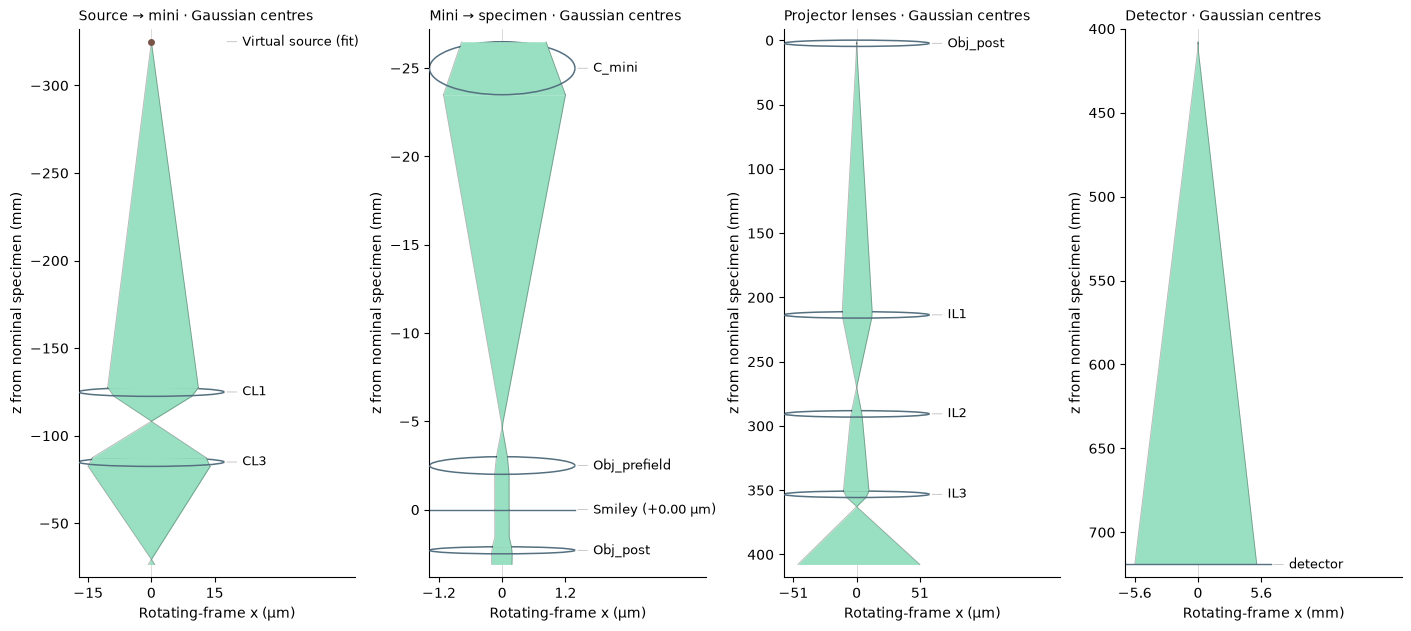

In [13]:
ray_fig, ray_axes = plt.subplots(1, 4, figsize=(14, 6.2), constrained_layout=True)
for section_index, ax in enumerate(ray_axes):
    demo.draw_rays(ax, height_nm=0., section=section_index)
plt.show()

### Interactive imaging and diffraction

Release sliders to render; contrast changes reuse the current image. **Reset focus**
returns the specimen to its nominal plane without changing lens currents.
The left panel is the nominal, zero-aberration reference for the selected optics
and viewing plane. Count, spot, aperture and magnification changes update it.

**View plane** selects **Detector image** or **IL1 crossover · diffraction**.
The virtual screen is located between IL1 and IL2 by the nominal specimen Fourier
condition A=0, including the finite IL1 lens length. Its position follows lens
settings but stays fixed when specimen height or aberrations change. The complete
Gaussian field propagates to the screen. Screen coordinates are in µm and span
nominal specimen frequencies ±0.12 nm⁻¹; enhanced gamma contrast reveals weak
features. An orange dotted line marks it in **Ray view → Projector lenses**.
PL1 is downstream and cannot affect this diffraction screen.

The **Gaussians** count controls specimen resolution. **Propagation** defaults
to continuous source propagation with automatic aperture recomposition when
needed. Explicit specimen recomposition is available as a comparison. With an
aperture, both use a resolved 512×512 illumination quadrature and a 256×256
complex-field interpolation grid. Those numerical counts are independent of
the specimen count.

**C aperture r** offers 10, 25, 80 and 150 µm radii, plus Out. The fitted model
provides the aperture plane, 0.15 µm sigmoid edge and the offsets for the two
measured aperture radii (10 and 25 µm). The larger radii are illustrative
extensions using the first fitted aperture centre.

**Spot size** selects a solved condenser operating point; its labels show the
aperture-out coherent specimen amplitude radius. Higher settings narrow the illuminated area.
**Magnification** selects 40k–600k and solves the imaging condition with the
fitted lens geometry and strengths. The physical 55 µm detector pitch stays fixed.

The green diagram follows sampled Gaussian centres downstream, including their
aberration updates. Without recomposition it traces the same source bundle;
with recomposition the upstream section is a back-mapped illumination guide.
The shaded range is not Gaussian width or a coherent intensity contour. A dashed
purple guide shows zero aberrations at the same height. Fixed section scales aid
comparison; **Specimen ±25 µm** makes height changes visible.

Open **Objective aberrations** and enable its three controls: C₁₂ in µm, C₂₁ in mm
and C₃₀ in m. **PL1 E** is the radial Seidel coefficient in 10⁹ m⁻³. These deliberately
large demonstration ranges reveal changes in this overview. Clear/uncheck the
objective controls to restore ideal transport while retaining other settings.

Historical source-basis error figures in `smiley_source_basis_checks.json` concern
the previous illustrative source and TOML geometry; they do not validate this
fitted-source model. The focus test above and current control tests use the new
model. Refine specimen and aperture sampling for quantitative work.


In [ ]:
%matplotlib widget
# Close only an earlier copy of this notebook's interactive panel when rerun.
if "live_fig" in globals():
    plt.close(live_fig)
if "controls" in globals():
    controls.close()

# A kernel may still hold the helper class from before viewing planes were added.
# Rerunning this cell repairs that stale instance without restarting the kernel.
from importlib import reload
from html import escape
import traceback
import smiley_defocus
if getattr(type(demo), "sampling_api_version", None) != 8:
    print("Refreshing the notebook helper and rebuilding the Gaussian model…")
    SmileyDefocus = reload(smiley_defocus).SmileyDefocus
    demo = SmileyDefocus(lattice_shape=demo.lattice_shape)
    focus, _, _ = demo.image(0.)

# A rerun starts from the documented optical defaults, retaining the basis count.
if demo.view_plane != "detector":
    demo = demo.with_view_plane("detector")
    focus, _, _ = demo.image(0.)
if (demo.spot_size, demo.magnification, demo.aperture_radius_m) != (3., 40000., None):
    demo = demo.with_settings(spot_size=3., magnification=40000., aperture_radius_m=None)
    focus, _, _ = demo.image(0.)

# Keep a separate compiled renderer and image cache for each selected basis.
# Reuse the same optics and specimen without repeating the imaging-condition solve.
base_demo = demo
sampling_options = {
    10_000: (100, 100), 50_000: (200, 250), 100_000: (250, 400),
    250_000: (500, 500), 500_000: (500, 1000), 1_000_000: (1000, 1000),
}
models_by_setting = {(base_demo.num_beams, 3., 40000., None, base_demo.propagation_mode, "detector"): base_demo}
gaussian_count = widgets.Dropdown(description="Gaussians", value=base_demo.num_beams,
    options=[(f"{count:,}", count) for count in sampling_options],
    style={"description_width": "100px"}, layout=widgets.Layout(width="280px"))

propagation_mode = widgets.Dropdown(description="Propagation", value=base_demo.propagation_mode,
    options=[("Source; resolve inserted aperture", "source"), ("Recompose at specimen", "recompose")],
    style={"description_width": "100px"}, layout=widgets.Layout(width="360px"))

view_plane = widgets.Dropdown(description="View plane", value="detector",
    options=[("Detector image", "detector"), ("IL1 crossover · diffraction", "il1_crossover")],
    style={"description_width": "100px"}, layout=widgets.Layout(width="400px"))

spot_size = widgets.SelectionSlider(description="Spot · radius", value=3.,
    options=[(f"{v:g} · ~{float(jnp.sqrt(2/(base_demo.source.k*jnp.imag(base_demo.nominal_illumination.Q_inv[0, 0]))))*1e9*2**((3-v)/2):.0f} nm", float(v)) for v in base_demo.spot_options],
    continuous_update=False, style={"description_width": "100px"}, layout=widgets.Layout(width="520px"))
magnification = widgets.SelectionSlider(description="Magnification", value=40000.,
    options=[(f"{v:,.0f}×", float(v)) for v in base_demo.magnification_options],
    continuous_update=False, style={"description_width": "100px"}, layout=widgets.Layout(width="520px"))
condenser_aperture = widgets.SelectionSlider(description="C aperture r", value=0.,
    options=[("Out", 0.)]+[(f"{r*1e6:g} µm", r) for r in base_demo.aperture_options],
    continuous_update=False, style={"description_width": "100px"}, layout=widgets.Layout(width="520px"))
projector_distortion = widgets.FloatSlider(description="PL1 E [10⁹ m⁻³]", value=0.,
    min=-100., max=100., step=2., continuous_update=False, readout_format="+.0f",
    style={"description_width": "165px"}, layout=widgets.Layout(width="520px"))

height = widgets.FloatSlider(value=0., min=-10., max=10., step=0.25,
    description="Height [µm]", continuous_update=False, readout_format="+.2f",
    style={"description_width": "100px"}, layout=widgets.Layout(width="520px"))
contrast = widgets.FloatSlider(value=1., min=0.4, max=1.8, step=0.05,
    description="Contrast γ", continuous_update=True,
    style={"description_width": "100px"}, layout=widgets.Layout(width="360px"))
reset = widgets.Button(description="Reset focus", icon="undo", layout=widgets.Layout(width="130px"))
ray_section = widgets.Dropdown(description="Ray view", value=2,
    options=[("Source → mini", 0), ("Mini → specimen", 1),
             ("Projector lenses", 2), ("Detector", 3), ("Specimen ±25 µm", 4)],
    style={"description_width": "70px"}, layout=widgets.Layout(width="300px"))
enable_aberrations = widgets.Checkbox(value=False, description="Enable objective aberrations")
aber_style = {"description_width": "165px"}
aber_layout = widgets.Layout(width="520px")
astigmatism = widgets.FloatSlider(value=0., min=-20., max=20., step=0.5,
    description="Astigmatism C₁₂ [µm]", continuous_update=False, disabled=True,
    style=aber_style, layout=aber_layout, readout_format="+.1f")
coma = widgets.FloatSlider(value=0., min=-50., max=50., step=1.,
    description="Coma C₂₁ [mm]", continuous_update=False, disabled=True,
    style=aber_style, layout=aber_layout, readout_format="+.1f")
spherical = widgets.FloatSlider(value=0., min=-100., max=100., step=1.,
    description="Spherical C₃₀ [m]", continuous_update=False, disabled=True,
    style=aber_style, layout=aber_layout, readout_format="+.1f")
clear_aberrations = widgets.Button(description="Clear aberrations", icon="undo")
aber_panel = widgets.Accordion(children=[widgets.VBox([
    enable_aberrations, astigmatism, coma, spherical, clear_aberrations,
    widgets.HTML("Large demonstration ranges for this 140 nm overview; axes fixed along specimen x."),
])], selected_index=None)
aber_panel.set_title(0, "Objective aberrations · KrivanekLens")
suspend_updates = False
status = widgets.HTML()
errors = widgets.Output()
with plt.ioff():
    live_fig, live_axes = plt.subplots(1, 3, figsize=(13.2, 5.6), constrained_layout=True,
        gridspec_kw={"width_ratios": [1, 1, 1.15]})
    reference_artist = live_axes[0].imshow(focus, origin=detector_origin, cmap="gray",
        extent=extent_mm, norm=PowerNorm(gamma=1., vmin=0., vmax=vmax))
    live_artist = live_axes[1].imshow(focus, origin=detector_origin, cmap="gray",
        extent=extent_mm, norm=PowerNorm(gamma=1., vmin=0., vmax=vmax))
    live_axes[0].set_title("Focused reference · 40,000×")
    live_axes[1].set_title("Sample height +0.00 µm")
    for ax in live_axes[:2]:
        ax.set(xlabel="Detector x [mm]", ylabel="Detector y [mm]")
    live_fig.canvas.toolbar_visible = False
    live_fig.canvas.header_visible = False
    live_fig.canvas.footer_visible = False

def current_aberrations():
    values = dict(projector_distortion=projector_distortion.value)
    if enable_aberrations.value:
        values.update(astigmatism_um=astigmatism.value, coma_mm=coma.value,
                      spherical_mm=spherical.value*1000.)
    return values

def update_display_geometry():
    diffraction = demo.view_plane == "il1_crossover"
    unit, scale = ("µm", 1e6) if diffraction else ("mm", 1e3)
    grid = demo.view_detector
    xy = np.asarray(grid.coords)
    dy, dx = map(float, grid.pixel_size)
    extent = np.array([xy[..., 0].min()-dx/2, xy[..., 0].max()+dx/2,
                       xy[..., 1].min()-dy/2, xy[..., 1].max()+dy/2])*scale
    for ax, artist in zip(live_axes[:2], (reference_artist, live_artist)):
        artist.set_extent(extent)
        ax.set(xlim=extent[:2], ylim=extent[2:],
               xlabel=f"Screen x [{unit}]", ylabel=f"Screen y [{unit}]")
    limit = float(focus.max()) if diffraction else vmax
    gamma = contrast.value*(.2 if diffraction else 1.)
    for artist in (reference_artist, live_artist):
        artist.set_norm(PowerNorm(gamma=gamma, vmin=0., vmax=limit))
    live_axes[0].set_title("Nominal diffraction reference" if diffraction
                           else f"Focused reference · {demo.magnification:,.0f}×")

def update_height(change=None):
    if suspend_updates:
        return
    status.value = f"Rendering {demo.num_beams:,} Gaussian beams…"
    try:
        frame, seconds, cached = demo.image(height.value * 1000., **current_aberrations())
        live_artist.set_data(frame)
        live_axes[1].set_title(f"{demo.view_label}\nSample height {height.value:+.2f} µm")
        update_display_geometry()
        demo.draw_rays(live_axes[2], height.value*1000., ray_section.value, **current_aberrations())
        live_fig.canvas.draw_idle()
        timing = "cached frame" if cached else f"{seconds*1000:.0f} ms compute + transfer"
        status.value = (f"<b>{demo.num_beams:,} beams · {demo.magnification:,.0f}× · "
                        f"spot {demo.spot_size:g} · {'aperture recomposition' if demo.aperture is not None else demo.propagation_mode} · 128 × 128</b> &nbsp; {timing}"
                        f"<br>{demo.view_label} · z = {float(demo.view_detector.z)*1000:.3f} mm"
                        + (" · PL1 is downstream of this screen" if demo.view_plane != "detector" else ""))
    except Exception as exc:
        status.value = "Render failed; the previous image is still displayed."
        with errors:
            print(f"{type(exc).__name__}: {exc}")
        raise

def update_settings(change=None):
    global demo, focus, suspend_updates
    if suspend_updates:
        return
    selectors = (gaussian_count, spot_size, magnification, condenser_aperture, propagation_mode, view_plane)
    key = tuple(widget.value for widget in selectors[:3]) + (condenser_aperture.value or None, propagation_mode.value, view_plane.value)
    previous = (demo.num_beams, demo.spot_size, demo.magnification, demo.aperture_radius_m, demo.propagation_mode, demo.view_plane)
    for widget in selectors:
        widget.disabled = True
    errors.outputs = ()
    status.value = "Preparing optics and focused reference (first use may compile)…"
    old_demo, old_focus = demo, focus
    old_frame = np.array(live_artist.get_array(), copy=True)
    old_titles = [ax.get_title() for ax in live_axes[:2]]
    try:
        candidate = models_by_setting.get(key)
        if candidate is None:
            candidate = demo if key[1:4] == previous[1:4] else base_demo.with_settings(
                spot_size=key[1], magnification=key[2], aperture_radius_m=key[3])
            if candidate.propagation_mode != key[4]:
                candidate = candidate.with_propagation_mode(key[4])
            if candidate.view_plane != key[5]:
                candidate = candidate.with_view_plane(key[5])
            if candidate.num_beams != key[0]:
                candidate = candidate.with_lattice_shape(sampling_options[key[0]])
        new_focus, _, _ = candidate.image(0.)
        frame, _, _ = candidate.image(height.value*1000., **current_aberrations())
        candidate.draw_rays(live_axes[2], height.value*1000., ray_section.value,
                            **current_aberrations())
        demo, focus = candidate, new_focus
        reference_artist.set_data(focus)
        live_artist.set_data(frame)
        live_axes[0].set_title(f"Focused reference · {demo.magnification:,.0f}×")
        models_by_setting[key] = candidate
        while len(models_by_setting) > 8:
            del models_by_setting[next(iter(models_by_setting))]
        update_height()
    except Exception as exc:
        demo, focus = old_demo, old_focus
        reference_artist.set_data(old_focus)
        live_artist.set_data(old_frame)
        update_display_geometry()
        for ax, title in zip(live_axes[:2], old_titles):
            ax.set_title(title)
        suspend_updates = True
        try:
            for widget, value in zip(selectors, previous):
                widget.value = 0. if widget is condenser_aperture and value is None else value
        finally:
            suspend_updates = False
        demo.draw_rays(live_axes[2], height.value*1000., ray_section.value,
                       **current_aberrations())
        status.value = (f"Setting change failed: <b>{escape(type(exc).__name__)}</b>: "
                        f"{escape(str(exc))}. Previous optics retained.")
        errors.append_stderr(traceback.format_exc())
        live_fig.canvas.draw_idle()
    finally:
        for widget in selectors:
            widget.disabled = False


def toggle_aberrations(change=None):
    for slider in (astigmatism, coma, spherical):
        slider.disabled = not enable_aberrations.value
    update_height()

def clear_objective(_):
    global suspend_updates
    suspend_updates = True
    try:
        astigmatism.value = coma.value = spherical.value = 0.
    finally:
        suspend_updates = False
    update_height()

def update_ray_view(change=None):
    demo.draw_rays(live_axes[2], height.value*1000., ray_section.value, **current_aberrations())
    live_fig.canvas.draw_idle()

def update_contrast(change=None):
    update_display_geometry()
    live_fig.canvas.draw_idle()

for selector in (gaussian_count, spot_size, magnification, condenser_aperture, propagation_mode, view_plane):
    selector.observe(update_settings, names="value")
projector_distortion.observe(update_height, names="value")
height.observe(update_height, names="value")
for slider in (astigmatism, coma, spherical):
    slider.observe(update_height, names="value")
enable_aberrations.observe(toggle_aberrations, names="value")
clear_aberrations.on_click(clear_objective)
contrast.observe(update_contrast, names="value")
ray_section.observe(update_ray_view, names="value")
reset.on_click(lambda _: setattr(height, "value", 0.))
optics_panel = widgets.Accordion(children=[widgets.VBox([
    spot_size, magnification, condenser_aperture, projector_distortion,
    widgets.HTML("Aperture labels are radii; fitted sigmoid edge = 0.15 µm. "
                 "Controls use the saved fitted microscope and native solenoids. PL1 E is a demonstration coefficient."),
])], selected_index=0)
optics_panel.set_title(0, "Condenser and projector")
controls = widgets.VBox([widgets.HBox([gaussian_count, propagation_mode]), view_plane, optics_panel, widgets.HBox([height, reset]), widgets.HBox([contrast, ray_section]), aber_panel, status,
                         live_fig.canvas, errors])
update_height()
display(controls)

RuntimeError: The Gaussian image is non-finite or empty.